# 02 · Entrenamiento y optimización — Detección de fraude (PaySim)

**Objetivo:** entrenar y optimizar modelos de clasificación para `isFraud`, registrar cada trial y cada modelo
en MLflow (DagsHub), elegir el threshold de decisión y registrar el modelo campeón en el Model Registry.

**Diseño**
- Datos: train = steps 1–312, test = steps 313–400 (notebook 01). Producción (401+) no se usa aquí.
- Validación: 4 folds *expanding window* por **días completos** dentro de train; cada fold valida un día y
  entrena con todos los anteriores.
- Submuestreo de legítimos (se conserva 10 %) **solo en los folds de entrenamiento**; validación y test conservan
  la proporción real.
- Métrica de optimización: **PR-AUC** (average precision). Accuracy no se usa.
- Optimización: **Optuna TPE + MedianPruner** frente a **Random Search** con el mismo presupuesto, más un estudio
  **AutoML** donde el algoritmo es un hiperparámetro.
- El test se usa **una sola vez**, al final, con el modelo y el threshold ya fijados.

In [1]:
import json
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from sklearn.metrics import average_precision_score

from fraud_detection import config
from fraud_detection.evaluate import (
    compute_metrics,
    expected_cost_curve,
    find_best_threshold,
    plot_confusion_matrix,
    plot_feature_importance,
    plot_pr_curve,
)
from fraud_detection.features import MODEL_FEATURES
from fraud_detection.plots import COLOR_FRAUD, COLOR_LEGIT, COLOR_NEUTRAL, finish, set_style
from fraud_detection.tracking import log_model_run, register_champion, setup_mlflow
from fraud_detection.train import (
    MODEL_NAMES,
    best_model_params,
    cross_validate,
    fit_model,
    get_feature_importance,
    run_study,
    study_history,
    temporal_day_folds,
)

os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"  # one link per run would flood the output
warnings.filterwarnings("ignore", module="mlflow")
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

QUICK = os.getenv("NB_QUICK") == "1"  # smoke-test mode with tiny budgets
tracking_uri = setup_mlflow(config.MLFLOW_EXPERIMENT_TRAINING)
config.OPTIMIZATION_REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"MLflow tracking: {tracking_uri} | experimento: {config.MLFLOW_EXPERIMENT_TRAINING} | QUICK={QUICK}")

/home/r_mejia/Project-MLEngineer3/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow tracking: https://dagshub.com/richardmk/ProjectMLEngineer3.mlflow | experimento: paysim-fraud-training | QUICK=False


## 1. Datos y folds temporales

In [2]:
cols = MODEL_FEATURES + ["step", "isFraud", "isFlaggedFraud"]
train = pd.read_parquet(config.TRAIN_PARQUET, columns=cols)
test = pd.read_parquet(config.TEST_PARQUET, columns=cols)
X_train, y_train = train[MODEL_FEATURES], train["isFraud"].to_numpy()
X_test, y_test = test[MODEL_FEATURES], test["isFraud"].to_numpy()

folds = temporal_day_folds(train["step"].to_numpy(), config.N_CV_FOLDS)
steps = train["step"].to_numpy()
fold_table = pd.DataFrame(
    [
        {
            "fold": k,
            "train_steps": f"1–{steps[tr].max()}",
            "val_steps": f"{steps[va].min()}–{steps[va].max()}",
            "train_filas": len(tr),
            "val_filas": len(va),
            "val_fraudes": int(y_train[va].sum()),
        }
        for k, (tr, va) in enumerate(folds)
    ]
)
val_idx = np.concatenate([va for _, va in folds])  # rows that receive out-of-fold predictions
print(f"Train: {len(train):,} filas ({y_train.mean():.4%} fraude) | Test: {len(test):,} filas ({y_test.mean():.4%})")
fold_table

Train: 1,918,423 filas (0.1835% fraude) | Test: 611,113 filas (0.1564%)


,fold,train_steps,val_steps,train_filas,val_filas,val_fraudes
0,0,1–216,217–240,1226487,171830,282
1,1,1–240,241–264,1398317,182109,262
2,2,1–264,265–288,1580426,149340,298
3,3,1–288,289–312,1729766,188657,242


## 2. Sanity checks: ¿por qué el PR-AUC es casi 1?

En la exploración inicial todos los modelos dieron PR-AUC ≈ 0.999. Antes de optimizar se verifica que no sea
leakage, con un LightGBM de referencia (parámetros fijos) sobre los mismos folds:

- **Labels barajados**: si el pipeline filtrara el target, el modelo seguiría acertando. Debe caer al azar.
- **Ablaciones**: quitar grupos de features para localizar de dónde viene la señal.
- **Reglas de negocio**: `is_full_drain` e `isFlaggedFraud` usadas directamente como score.

In [3]:
SANITY_PARAMS = {"n_estimators": 300, "learning_rate": 0.1, "num_leaves": 31, "min_child_samples": 20,
                 "subsample": 0.8, "colsample_bytree": 0.8, "reg_lambda": 1.0, "scale_pos_weight": 5.0}
orig_info = ["oldbalanceOrg", "newbalanceOrig", "orig_balance_diff", "orig_balance_error",
             "amount_to_orig_balance_ratio", "is_orig_balance_zero", "is_full_drain"]
post_tx = ["newbalanceOrig", "newbalanceDest", "orig_balance_diff", "orig_balance_error", "dest_balance_diff",
           "dest_balance_error", "is_dest_balance_zero", "is_full_drain"]
ablations = {
    "all_features": ("Modelo con las 15 features", MODEL_FEATURES),
    "no_full_drain": ("Sin is_full_drain", [f for f in MODEL_FEATURES if f != "is_full_drain"]),
    "pre_tx_only": ("Solo info previa a la transacción", [f for f in MODEL_FEATURES if f not in post_tx]),
    "no_orig_balance": ("Sin info del saldo origen", [f for f in MODEL_FEATURES if f not in orig_info]),
    "amount_type_hour": ("Solo amount + tipo + hora", ["amount", "is_transfer", "hour_of_day"]),
}
rows = []
for key, (label, feats) in ablations.items():
    scores, _ = cross_validate("lightgbm", SANITY_PARAMS, X_train[feats], y_train, folds, config.NEGATIVE_FRACTION)
    rows.append({"id": key, "experimento": label, "n_features": len(feats), "cv_pr_auc": np.mean(scores), "min_fold": np.min(scores)})

y_shuffled = np.random.default_rng(config.SEED).permutation(y_train)
scores, _ = cross_validate("lightgbm", SANITY_PARAMS, X_train, y_shuffled, folds, config.NEGATIVE_FRACTION)
rows.append({"id": "shuffled_labels", "experimento": "Labels barajados (test de leakage)", "n_features": 15,
             "cv_pr_auc": np.mean(scores), "min_fold": np.min(scores)})
for rule in ["is_full_drain", "isFlaggedFraud"]:
    scores = [average_precision_score(y_train[va], train[rule].to_numpy()[va]) for _, va in folds]
    rows.append({"id": f"rule_{rule}", "experimento": f"Regla {rule} como score", "n_features": 1,
                 "cv_pr_auc": np.mean(scores), "min_fold": np.min(scores)})

sanity = pd.DataFrame(rows)
sanity.to_csv(config.OPTIMIZATION_REPORTS_DIR / "sanity_checks.csv", index=False)
log_model_run(
    "sanity-checks",
    params={"reference_model": "lightgbm", **SANITY_PARAMS},
    metrics={f"{r.id}_cv_pr_auc": r.cv_pr_auc for r in sanity.itertuples()} | {"base_rate": y_train.mean()},
    tags={"stage": "sanity"},
    tables={"sanity_checks": sanity},
)
sanity.drop(columns="id")

,experimento,n_features,cv_pr_auc,min_fold
0,Modelo con las 15 features,15,0.9988,0.9953
1,Sin is_full_drain,14,0.9986,0.9946
2,Solo info previa a la transacción,7,0.9838,0.9427
3,Sin info del saldo origen,8,0.7582,0.7123
4,Solo amount + tipo + hora,3,0.3187,0.2694
5,Labels barajados (test de leakage),15,0.0019,0.0017
6,Regla is_full_drain como score,1,0.9751,0.9733
7,Regla isFlaggedFraud como score,1,0.0034,0.0013


**Conclusión: no hay leakage; el resultado casi perfecto es un artefacto del simulador.**
- Con **labels barajados** el PR-AUC cae a 0.0019 ≈ tasa base (0.0018): el pipeline no filtra el target.
- La **regla `is_full_drain` sola** logra 0.975; el modelo completo 0.9988 → el modelo agrega ~2.4 puntos.
- **Quitar `is_full_drain`** no cambia nada (0.9986): el árbol la reconstruye con `amount` y `oldbalanceOrg`.
- **Solo con información previa a la transacción** se logra 0.984: los saldos posteriores no explican el
  rendimiento, lo que descarta leakage por información post-evento.
- **Sin el saldo del origen** cae a 0.758, y con solo monto/tipo/hora a 0.319: la señal está en la relación
  monto ↔ saldo del origen (el agente fraudulento de PaySim vacía la cuenta).

**Decisión:** se continúa con las 15 features y el modelo se compara siempre contra la regla `is_full_drain`.

## 3. Baselines de negocio (reglas)

In [4]:
baselines = {}
for rule in ["isFlaggedFraud", "is_full_drain"]:
    score = train[rule].to_numpy()[val_idx].astype(float)
    m = compute_metrics(y_train[val_idx], score, threshold=0.5)
    fig = plot_confusion_matrix(y_train[val_idx], score, 0.5, f"Regla {rule} (días de validación)")
    log_model_run(f"baseline-rule-{rule}", params={"rule": rule}, metrics={f"cv_{k}": v for k, v in m.items()},
                  tags={"stage": "baseline"}, figures={"confusion_matrix_cv": fig})
    plt.close(fig)
    baselines[rule] = m
pd.DataFrame(baselines).T[["pr_auc", "precision", "recall", "f1", "f2", "tp", "fp", "fn"]]

,pr_auc,precision,recall,f1,f2,tp,fp,fn
isFlaggedFraud,0.0034,1.0000,0.0018,0.0037,0.0023,2.0000,0.0000,"1,082.0000"
is_full_drain,0.9751,1.0000,0.9751,0.9874,0.9800,"1,057.0000",0.0000,27.0000


`is_full_drain` es el baseline a superar: precision perfecta con recall ~97.5 %. El aporte del modelo está en
el ~2.5 % de fraudes que **no** vacían la cuenta, sin sacrificar precision. `isFlaggedFraud` es casi inútil
(recall < 1 %).

## 4. Optimización de hiperparámetros

### Espacios de búsqueda (`train.suggest_params`)

| Modelo | Hiperparámetros | Justificación |
|---|---|---|
| Logistic Regression | `C` ∈ [1e-3, 1e2] log, `class_weight` ∈ {None, balanced} | Regularización en escala log; el pipeline imputa, aplica log con signo y estandariza (ajustado solo en el fold de train) |
| Random Forest | `n_estimators` 50–200, `max_depth` 6–16, `min_samples_leaf` 1–50 log, `max_features` 0.3–1, `class_weight` | Espacio acotado: un CV de RF cuesta ~10× uno de boosting |
| XGBoost | `n_estimators` 100–600, `learning_rate` 0.01–0.3 log, `max_depth` 3–10, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda` log, `scale_pos_weight` 1–50 log | Complejidad de árbol limitada para no sobreajustar ~3.5 K fraudes; peso de la clase positiva buscado porque el submuestreo ya cambia la proporción |
| LightGBM | Igual que XGBoost con `num_leaves` 8–128 log y `min_child_samples` 5–200 log en lugar de profundidad | Ídem |

### Estrategias
- **TPE (bayesiano, multivariado)**: modela qué regiones del espacio dan buen PR-AUC y propone ahí los siguientes
  trials. Con **MedianPruner**, un trial se corta si tras un fold su PR-AUC acumulado queda por debajo de la mediana
  de trials previos en ese fold (ahorra cómputo).
- **Random Search**: muestreo uniforme del mismo espacio, sin poda. Es el baseline de optimización.

Cada trial se registra como **run anidado** en MLflow (params, PR-AUC por fold, estado COMPLETE/PRUNED, duración).

In [5]:
BUDGET = {"logreg": 10, "random_forest": 5, "xgboost": 15, "lightgbm": 15, "automl": 25}
if QUICK:
    BUDGET = {k: 2 for k in BUDGET}

studies = {}
for name in MODEL_NAMES:
    t0 = time.perf_counter()
    studies[f"{name}-tpe"] = run_study(f"optuna-tpe-{name}", [name], X_train, y_train, folds, BUDGET[name],
                                       sampler="tpe", negative_fraction=config.NEGATIVE_FRACTION)
    print(f"{name:14s} TPE    best={studies[f'{name}-tpe'].best_value:.4f}  ({time.perf_counter() - t0:,.0f}s)")
for name in ["xgboost", "lightgbm"]:
    t0 = time.perf_counter()
    studies[f"{name}-random"] = run_study(f"random-search-{name}", [name], X_train, y_train, folds, BUDGET[name],
                                          sampler="random", negative_fraction=config.NEGATIVE_FRACTION)
    print(f"{name:14s} Random best={studies[f'{name}-random'].best_value:.4f}  ({time.perf_counter() - t0:,.0f}s)")

logreg         TPE    best=0.9981  (111s)


random_forest  TPE    best=0.9989  (312s)


xgboost        TPE    best=0.9990  (179s)


lightgbm       TPE    best=0.9989  (268s)


xgboost        Random best=0.9990  (222s)


lightgbm       Random best=0.9989  (215s)


In [6]:
histories = {key: study_history(s) for key, s in studies.items()}
summary = pd.DataFrame(
    {
        key: {
            "mejor_cv_pr_auc": s.best_value,
            "trials": len(h),
            "podados": int((h["state"] == "PRUNED").sum()),
            "tiempo_total_s": h["duration_s"].sum(),
            "trial_del_mejor": int(s.best_trial.number),
        }
        for (key, s), h in zip(studies.items(), histories.values(), strict=True)
    }
).T
pd.concat(histories, names=["study"]).to_csv(config.OPTIMIZATION_REPORTS_DIR / "study_histories.csv")
summary.to_csv(config.OPTIMIZATION_REPORTS_DIR / "study_summary.csv")
summary

,mejor_cv_pr_auc,trials,podados,tiempo_total_s,trial_del_mejor
logreg-tpe,0.9981,10.0000,1.0000,102.7848,5.0000
random_forest-tpe,0.9989,5.0000,0.0000,311.3688,2.0000
xgboost-tpe,0.9990,15.0000,6.0000,181.6593,12.0000
lightgbm-tpe,0.9989,15.0000,3.0000,276.1821,14.0000
xgboost-random,0.9990,15.0000,0.0000,229.1577,3.0000
lightgbm-random,0.9989,15.0000,0.0000,219.5788,6.0000


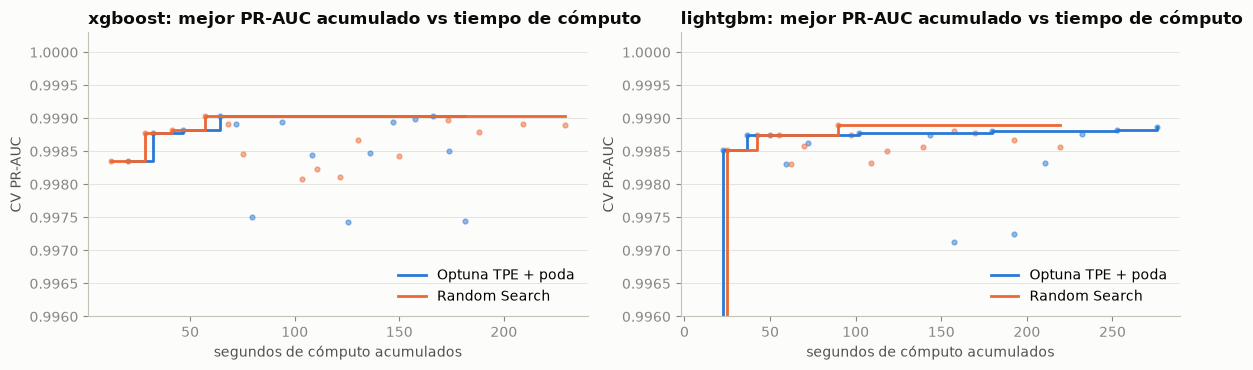

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, name in zip(axes, ["xgboost", "lightgbm"], strict=True):
    for sampler, color, label in [("tpe", COLOR_LEGIT, "Optuna TPE + poda"), ("random", COLOR_FRAUD, "Random Search")]:
        h = histories[f"{name}-{sampler}"]
        ax.step(h["cumulative_s"], h["best_so_far"], where="post", color=color, label=label)
        ax.scatter(h["cumulative_s"], h["value"], color=color, s=12, alpha=0.5)
    ax.set_ylim(0.996, 1.0003)  # a few degenerate trials (PR-AUC ~0.5) fall below the axis
    ax.legend(loc="lower right")
    finish(ax, f"{name}: mejor PR-AUC acumulado vs tiempo de cómputo", "segundos de cómputo acumulados", "CV PR-AUC")
fig.tight_layout()
plt.show()

**Lectura de la optimización**
- El problema está **saturado**: todos los algoritmos quedan entre 0.998 y 0.999 de PR-AUC CV y las diferencias
  entre los mejores (≤ 0.0002) son menores que la variación entre folds. Ningún método de búsqueda puede mostrar una
  mejora grande de score, así que la comparación relevante es de **eficiencia**:
  - **XGBoost:** TPE llegó al mismo mejor valor que Random Search (0.9990) **podando 6 de 15 trials** y con 182 s
    de cómputo frente a 229 s (**−21 %**).
  - **LightGBM:** TPE podó 3 trials pero tardó más (276 s vs 220 s): concentró la búsqueda en configuraciones con
    más árboles, más caras, sin mejorar el valor (0.9989 en ambos).
- Con presupuestos cortos (15 trials) y un objetivo saturado, TPE tiene poco margen para diferenciarse; su ventaja
  aparece en espacios grandes con objetivos no saturados. La **poda** sí ahorra cómputo cuando hay trials claramente
  peores (XGBoost).
- Random Forest (0.9989) iguala a boosting pero cuesta ~62 s por trial frente a ~12–18 s: no compensa.

## 5. AutoML (Reto ML 1)

Un solo estudio TPE donde **el algoritmo es un hiperparámetro categórico** y cada algoritmo tiene su propio
sub-espacio (espacio condicional). Optuna decide en qué algoritmo gastar el presupuesto. Se excluye Random Forest por
costo (~10× por trial) tras verificar en la sección 4 que no supera a los modelos de boosting.

In [8]:
t0 = time.perf_counter()
automl_models = ["logreg", "xgboost", "lightgbm"]
studies["automl-tpe"] = run_study("automl-tpe", automl_models, X_train, y_train, folds, BUDGET["automl"],
                                  sampler="tpe", negative_fraction=config.NEGATIVE_FRACTION)
automl_hist = study_history(studies["automl-tpe"])
automl_hist.to_csv(config.OPTIMIZATION_REPORTS_DIR / "automl_history.csv", index=False)
automl_name, automl_params = best_model_params(studies["automl-tpe"])
print(f"AutoML: mejor algoritmo = {automl_name}, CV PR-AUC = {studies['automl-tpe'].best_value:.4f} "
      f"({time.perf_counter() - t0:,.0f}s)")
automl_hist.groupby("model").agg(trials=("trial", "size"), mejor=("value", "max"),
                                 podados=("state", lambda s: (s == "PRUNED").sum()))

AutoML: mejor algoritmo = xgboost, CV PR-AUC = 0.9991 (227s)


,trials,mejor,podados
model,,,
lightgbm,4,0.9984,3
logreg,4,0.9981,1
xgboost,17,0.9991,6


El estudio AutoML asignó **17 de 25 trials a XGBoost**, 4 a LightGBM y 4 a Logistic Regression: TPE detectó
rápido qué algoritmo rinde mejor y concentró ahí el presupuesto. Su mejor trial (XGBoost, 0.9991) coincide con el
ganador de la búsqueda por algoritmo, lo que valida la selección de forma independiente.

## 6. Candidatos por algoritmo

Para cada algoritmo se toman los mejores hiperparámetros encontrados (TPE, Random o AutoML) y se:
1. recalculan las predicciones **out-of-fold** (OOF) en los 4 días de validación;
2. elige el threshold que maximiza **F2** sobre esas predicciones OOF;
3. reentrena con todo train y registra en MLflow el modelo, las métricas CV y los artefactos (curva PR, matriz de
   confusión y feature importance).

El test sigue sin usarse.

In [9]:
def best_trial_for(name: str) -> tuple[float, dict]:
    best_value, best_params = -np.inf, None
    for s in studies.values():
        for t in s.trials:
            if t.state != optuna.trial.TrialState.COMPLETE or t.value is None:
                continue
            t_model = t.params.get("model", s.user_attrs.get("model"))
            if t_model == name and t.value > best_value:
                prefix = f"{name}__"
                best_value = t.value
                best_params = {k.removeprefix(prefix): v for k, v in t.params.items() if k != "model"}
    return best_value, best_params


candidates, oof_scores = {}, {}
for name in MODEL_NAMES:
    best_value, params = best_trial_for(name)
    scores, oof = cross_validate(name, params, X_train, y_train, folds, config.NEGATIVE_FRACTION)
    y_val, s_val = y_train[val_idx], oof[val_idx]
    threshold, _ = find_best_threshold(y_val, s_val, beta=2)
    m = compute_metrics(y_val, s_val, threshold)
    model = fit_model(name, params, X_train, y_train, config.NEGATIVE_FRACTION)
    importance = get_feature_importance(model, MODEL_FEATURES)
    figs = {
        "pr_curve_cv": plot_pr_curve({name: (y_val, s_val)}, y_val.mean()),
        "confusion_matrix_cv": plot_confusion_matrix(y_val, s_val, threshold, f"{name} · OOF"),
        "feature_importance": plot_feature_importance(importance, f"{name} · feature importance"),
    }
    run_id, model_uri = log_model_run(
        f"candidate-{name}",
        params={"model": name, "threshold": threshold, "negative_fraction": config.NEGATIVE_FRACTION, **params},
        metrics={f"cv_{k}": v for k, v in m.items()} | {f"fold{i}_pr_auc": s for i, s in enumerate(scores)},
        tags={"stage": "candidate", "model": name},
        figures=figs,
        tables={"feature_importance": importance.rename("importance").rename_axis("feature").reset_index()},
        model=model,
        input_example=X_train.head(5),
    )
    for f in figs.values():
        plt.close(f)
    oof_scores[name] = s_val
    candidates[name] = {"params": params, "threshold": threshold, "model": model, "run_id": run_id,
                        "model_uri": model_uri, "importance": importance, **m}

cand_table = pd.DataFrame(candidates).T[["pr_auc", "roc_auc", "precision", "recall", "f1", "f2", "fp", "fn", "threshold"]]
cand_table = cand_table.astype(float).sort_values(["pr_auc", "f2"], ascending=False)
cand_table.to_csv(config.OPTIMIZATION_REPORTS_DIR / "candidates_cv.csv")
cand_table

2026/10/20 20:38:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/20 20:38:49 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/10/20 20:41:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/20 20:41:46 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/10/20 20:42:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/20 20:42:32 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/10/20 20:44:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/20 20:44:35 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


,pr_auc,roc_auc,precision,recall,f1,f2,fp,fn,threshold
xgboost,0.9990,1.0000,1.0000,0.9963,0.9982,0.9970,0.0000,4.0000,0.8275
lightgbm,0.9989,0.9999,1.0000,0.9963,0.9982,0.9970,0.0000,4.0000,0.9917
random_forest,0.9987,0.9997,1.0000,0.9963,0.9982,0.9970,0.0000,4.0000,0.7050
logreg,0.9980,0.9994,1.0000,0.9963,0.9982,0.9970,0.0000,4.0000,0.9674


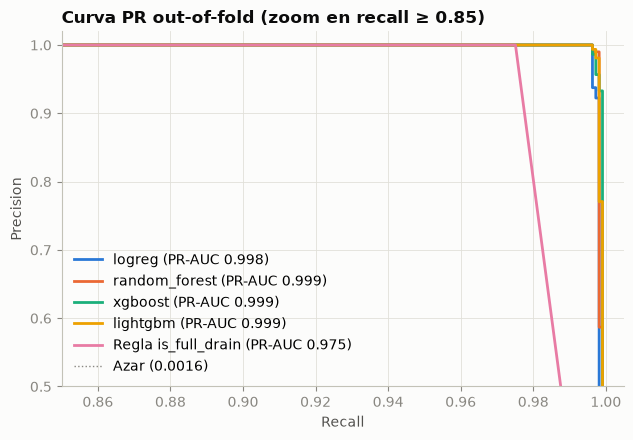

In [10]:
curves = {name: (y_train[val_idx], s) for name, s in oof_scores.items()}
curves["Regla is_full_drain"] = (y_train[val_idx], train["is_full_drain"].to_numpy()[val_idx].astype(float))
fig = plot_pr_curve(curves, y_train[val_idx].mean())
fig.axes[0].set_xlim(0.85, 1.005)
fig.axes[0].set_ylim(0.5, 1.02)
fig.axes[0].set_title("Curva PR out-of-fold (zoom en recall ≥ 0.85)")
plt.show()

**Selección del campeón:** mayor PR-AUC out-of-fold; en caso de empate práctico, mayor F2 en su threshold.

In [11]:
champion_name = cand_table.index[0]
champion = candidates[champion_name]
print(f"Campeón: {champion_name} | CV PR-AUC {champion['pr_auc']:.4f} | threshold F2 {champion['threshold']:.4f}")
pd.Series(champion["params"], name="hiperparámetros").to_frame()

Campeón: xgboost | CV PR-AUC 0.9990 | threshold F2 0.8275


,hiperparámetros
n_estimators,150.0000
learning_rate,0.1604
max_depth,3.0000
min_child_weight,1.2031
subsample,0.8544
colsample_bytree,0.7900
reg_lambda,0.0040
scale_pos_weight,1.9059


## 7. Threshold de decisión

Un score no es una decisión: hay que fijar a partir de qué probabilidad se bloquea o revisa una transacción.

- **Criterio elegido: maximizar F2** en las predicciones OOF. F2 pondera el recall 2× más que la precision, porque
  un fraude no detectado (se pierde el monto completo, en promedio > 1 M) es mucho más costoso que una falsa alarma
  (una revisión manual).
- **Robustez:** todo threshold dentro del hueco entre dos scores consecutivos produce las mismas predicciones, así
  que el óptimo de F2 es un **intervalo**. Se toma su **punto medio** en lugar del borde, para tener margen ante
  pequeños cambios de score en producción (drift).
- **Contraste con una curva de costo**: costo total = monto de los fraudes no detectados + costo de revisión por
  cada transacción marcada. Se asume un costo de revisión de 1,000 unidades monetarias.

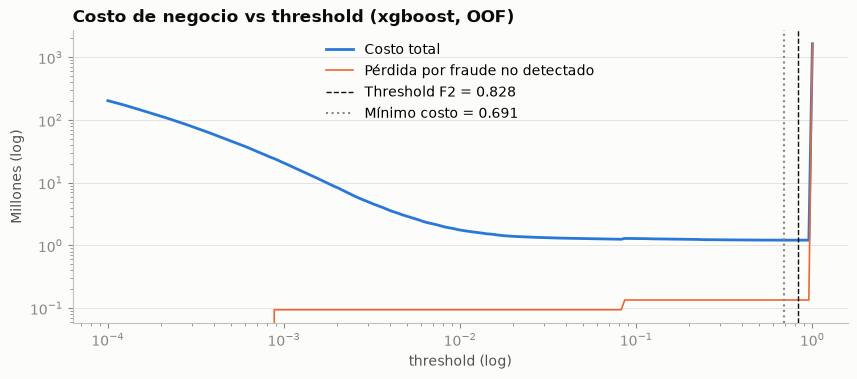

,precision,recall,f2,tp,fp,fn,costo_total_M
F2 (elegido),1.0000,0.9963,0.9970,"1,080.0000",0.0000,4.0000,1.2150
Mínimo costo,1.0000,0.9963,0.9970,"1,080.0000",0.0000,4.0000,1.2150
0.5 (default),0.9963,0.9963,0.9963,"1,080.0000",4.0000,4.0000,1.2190


In [12]:
REVIEW_COST = 1_000.0
amount_val = X_train["amount"].to_numpy()[val_idx]
s_val = oof_scores[champion_name]
y_val = y_train[val_idx]
costs = expected_cost_curve(y_val, s_val, amount_val, REVIEW_COST)
cost_best = costs.loc[costs["total_cost"].idxmin()]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(costs["threshold"], costs["total_cost"] / 1e6, color=COLOR_LEGIT, label="Costo total")
ax.plot(costs["threshold"], costs["fraud_loss"] / 1e6, color=COLOR_FRAUD, linewidth=1.2, label="Pérdida por fraude no detectado")
ax.axvline(champion["threshold"], color="#0b0b0b", linestyle="--", linewidth=1, label=f"Threshold F2 = {champion['threshold']:.3f}")
ax.axvline(cost_best["threshold"], color=COLOR_NEUTRAL, linestyle=":", linewidth=1.5, label=f"Mínimo costo = {cost_best['threshold']:.3f}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(loc="upper center")
finish(ax, f"Costo de negocio vs threshold ({champion_name}, OOF)", "threshold (log)", "Millones (log)")
plt.show()

compare_thr = pd.DataFrame({
    "F2 (elegido)": compute_metrics(y_val, s_val, champion["threshold"]),
    "Mínimo costo": compute_metrics(y_val, s_val, cost_best["threshold"]),
    "0.5 (default)": compute_metrics(y_val, s_val, 0.5),
}).T
compare_thr["costo_total_M"] = [
    (amount_val[(y_val == 1) & (s_val < t)].sum() + (s_val >= t).sum() * REVIEW_COST) / 1e6
    for t in [champion["threshold"], cost_best["threshold"], 0.5]
]
compare_thr[["precision", "recall", "f2", "tp", "fp", "fn", "costo_total_M"]]

- El threshold elegido (**0.828**) es el punto medio del intervalo óptimo de F2. El mínimo de la curva de costo
  (0.691) cae dentro del mismo intervalo y produce exactamente la misma matriz de confusión (0 FP, 4 FN).
- Con el threshold por defecto de 0.5 aparecerían 4 falsos positivos sin detectar ningún fraude adicional.
- La curva de costo es **plana en un rango amplio (≈ 0.01–0.98)**, así que la decisión es estable. El costo solo se
  dispara cerca de 1.0 (fraudes no detectados) y por debajo de ~0.01 (revisiones innecesarias).
- El costo total (~1.2 M) lo dominan las revisiones de los ~1,080 fraudes marcados. Los 4 fraudes perdidos suman
  ~0.14 M.

## 8. Evaluación final en test (steps 313–400) y registro del campeón

Se evalúa **una sola vez**: el modelo ya reentrenado con todo train y el threshold fijado con OOF.

In [13]:
model = champion["model"]
threshold = champion["threshold"]
test_scores = model.predict_proba(X_test)[:, 1]
test_m = compute_metrics(y_test, test_scores, threshold)

rule_scores = {r: test[r].to_numpy().astype(float) for r in ["is_full_drain", "isFlaggedFraud"]}
test_table = pd.DataFrame(
    {f"Modelo {champion_name}": test_m}
    | {f"Regla {r}": compute_metrics(y_test, s, 0.5) for r, s in rule_scores.items()}
).T
test_table.loc[f"Modelo {champion_name} (CV OOF)"] = pd.Series({k: champion[k] for k in test_m})
test_table = test_table[["pr_auc", "roc_auc", "precision", "recall", "f1", "f2", "tp", "fp", "fn"]]
test_table.to_csv(config.OPTIMIZATION_REPORTS_DIR / "test_results.csv")
test_table

,pr_auc,roc_auc,precision,recall,f1,f2,tp,fp,fn
Modelo xgboost,1.0000,1.0000,1.0000,0.9990,0.9995,0.9992,955.0000,0.0000,1.0000
Regla is_full_drain,0.9833,0.9916,1.0000,0.9833,0.9916,0.9866,940.0000,0.0000,16.0000
Regla isFlaggedFraud,0.0026,0.5005,1.0000,0.0010,0.0021,0.0013,1.0000,0.0000,955.0000
Modelo xgboost (CV OOF),0.9990,1.0000,1.0000,0.9963,0.9982,0.9970,"1,080.0000",0.0000,4.0000


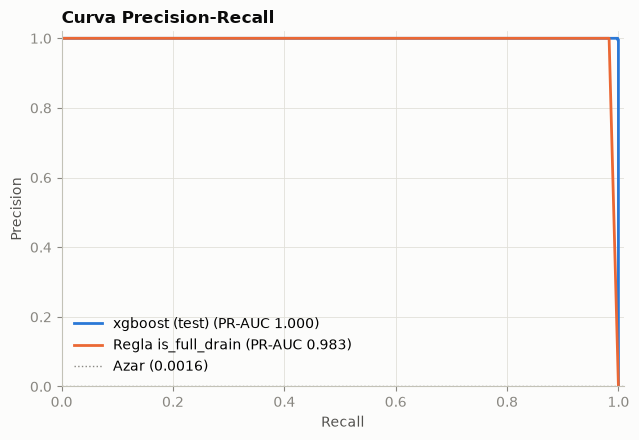

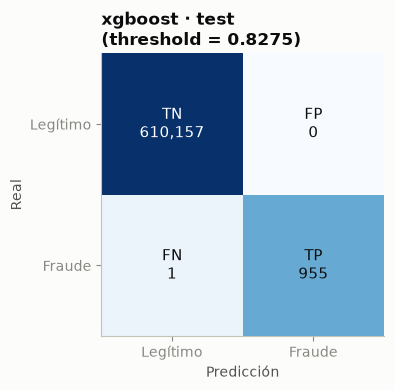

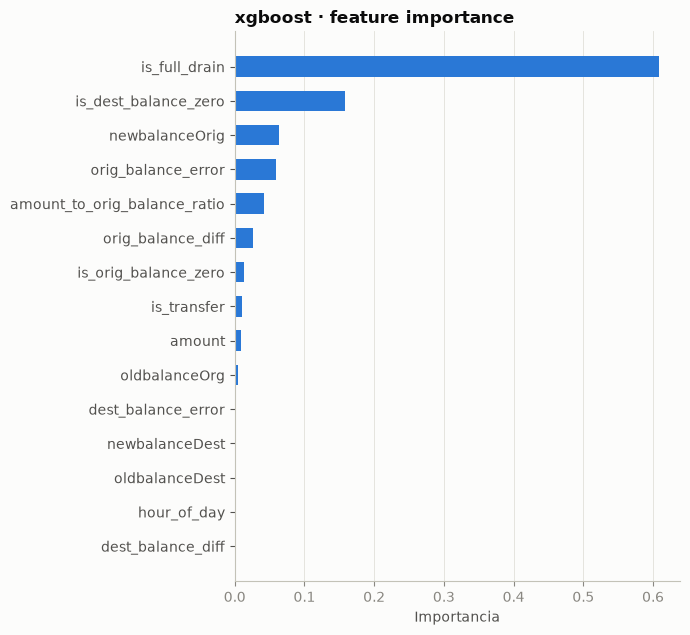

In [14]:
fig_pr = plot_pr_curve({f"{champion_name} (test)": (y_test, test_scores),
                        "Regla is_full_drain": (y_test, rule_scores["is_full_drain"])}, y_test.mean())
fig_cm = plot_confusion_matrix(y_test, test_scores, threshold, f"{champion_name} · test")
fig_fi = plot_feature_importance(champion["importance"], f"{champion_name} · feature importance")
plt.show()

In [15]:
run_id, model_uri = log_model_run(
    f"champion-{champion_name}",
    params={"model": champion_name, "threshold": threshold, "negative_fraction": config.NEGATIVE_FRACTION,
            "train_steps": f"1-{config.TRAIN_MAX_STEP}", "test_steps": f"{config.TRAIN_MAX_STEP + 1}-{config.REFERENCE_MAX_STEP}",
            **champion["params"]},
    metrics={f"test_{k}": v for k, v in test_m.items()} | {f"cv_{k}": champion[k] for k in test_m},
    tags={"stage": "champion", "model": champion_name},
    figures={"pr_curve_test": fig_pr, "confusion_matrix_test": fig_cm, "feature_importance": fig_fi},
    tables={"test_results": test_table.reset_index(names="modelo")},
    model=model,
    input_example=X_train.head(5),
)
version = register_champion(model_uri, config.REGISTERED_MODEL_NAME, config.CHAMPION_ALIAS)

config.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(model, config.CHAMPION_MODEL_PATH)
meta = {"model_name": champion_name, "params": champion["params"], "threshold": threshold,
        "features": MODEL_FEATURES, "negative_fraction": config.NEGATIVE_FRACTION, "mlflow_run_id": run_id,
        "registered_model": config.REGISTERED_MODEL_NAME, "version": version, "alias": config.CHAMPION_ALIAS,
        "cv_pr_auc": champion["pr_auc"], "test_metrics": test_m}
config.CHAMPION_META_PATH.write_text(json.dumps(meta, indent=2, default=float))
print(f"Registrado {config.REGISTERED_MODEL_NAME} v{version} con alias '{config.CHAMPION_ALIAS}' (run {run_id})")

2026/10/20 20:45:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/20 20:45:12 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'paysim-fraud-detector' already exists. Creating a new version of this model...


2026/10/20 20:45:52 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: paysim-fraud-detector, version 2


Created version '2' of model 'paysim-fraud-detector'.


Registrado paysim-fraud-detector v2 con alias 'champion' (run 424475cd6a6b4a1d9cd0f77827886a61)


## 9. Conclusiones

- **Campeón: XGBoost** (150 árboles, profundidad 3, learning rate 0.16, `scale_pos_weight` ≈ 1.9), elegido por el
  mayor PR-AUC out-of-fold (0.9990) y confirmado de forma independiente por el estudio AutoML.
- **Test (steps 313–400, evaluación única)**: PR-AUC **0.999995**, recall **99.9 %** (955 de 956 fraudes) y
  **0 falsos positivos** con threshold 0.828.
- **Contra la regla `is_full_drain`** (recall 98.3 %, 16 fraudes perdidos), el modelo detecta 15 fraudes más sin
  agregar falsas alarmas. `isFlaggedFraud` detecta 1 de 956.
- **CV y test son consistentes** (0.9990 vs 0.99999): no hay señales de sobreajuste al esquema de validación.
- ⚠️ **Advertencia:** un PR-AUC ≈ 1 solo es posible porque PaySim genera el fraude con un patrón determinista
  (vaciar la cuenta). En datos reales este nivel no sería creíble; la sección 2 lo documenta. El valor práctico del
  modelo está en los casos que la regla no cubre.
- **Registro:** `paysim-fraud-detector` v2 en el Model Registry de DagsHub con alias `champion`, más una copia local
  en `models/` para los notebooks 03 y 04.
- **Riesgos a monitorear (Fase 4):** el prior shift (tasa de fraude ~9× en steps ≥ 401) y la dependencia de una sola
  relación (`amount ≈ oldbalanceOrg`); si el patrón de fraude cambia, el modelo se degradará rápido.